# Key results from the thesis

The original goal of this thesis was to assess the cross-simulation robustness of Neural Posterior Estimation (NPE). Our results show that it depends on the feature. Some features transfer well across simulations, whilst others risk the model producing overconfident posteriors and losing calibration when transferring.

Stellar velocity dispersion and absolute stellar mass improve within-simulation prediction but are sensitive to simulation transfer. The population and ablation differences exceed their sample-size references; classifier-defined common support does not remove the absolute-stellar bias. A training-calibrated normalization shift removes much of that bias, whilst the observed Local Group estimates remain simulation-dependent. This notebook collects the key numbers from the thesis's Results and Discussion chapters. It uses the small result tables included in the repository and does not train or load a model.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(name):
    return pd.read_csv(ROOT / 'results' / name)
def record(name):
    return json.loads((ROOT / 'results' / name).read_text(encoding='utf-8'))

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
counts = table('populations/pair_counts.csv').set_index('domain')
assert counts['n'].to_dict() == {'flamingo': 142713, 'tng': 1530}
ks = record('bootstrap/population_reference.json')['theta_marginal']
assert np.isclose(ks['p_value'], 1 / 501)
display(counts.rename(columns={'n':'Pairs','same_host':'Same-host','different_host':'Different-host',
                              'median_log_mass':'Median log10 mass'}).round(3))
display(Markdown(f"The target-mass distributions differ by **{counts.loc['tng','median_log_mass']-counts.loc['flamingo','median_log_mass']:.3f} dex** in their medians. The observed KS statistic is **{ks['ks_real']:.4f}**. None of 500 TNG-sized FLAMINGO subsamples reaches it: the plus-one reference p value is **1/501 ≈ {ks['p_value']:.3f}**."))
refits = table('bootstrap/posterior_subsampling_repeats.csv')
refits = refits.loc[refits.block == 'core_dynamics', 'jsd_vs_full'].to_numpy()
observed_jsd = record('bootstrap/observed_jsd.json')['core_dynamics']['jsd_full']
core_jsd_p = (1 + np.count_nonzero(refits >= observed_jsd)) / (len(refits) + 1)
assert len(refits) == 200 and np.isclose(core_jsd_p, 51/201)


,Pairs,Same-host,Different-host,Median log10 mass
domain,,,,
flamingo,142713,63071,79642,12.401
tng,1530,1253,277,12.645


The target-mass distributions differ by **0.244 dex** in their medians. The observed KS statistic is **0.3064**. None of 500 TNG-sized FLAMINGO subsamples reaches it: the plus-one reference p value is **1/501 ≈ 0.002**.

## Population differences are not explained by the tested sample-size reduction

FLAMINGO contains 142713 selected pairs, compared to 1530 in TNG300. Because of the varying sizes of pairs within the simulations, it becomes important to check if the results are due to the pair mismatch or because of genuine simulation differences.

The median target mass is 12.401 for FLAMINGO and 12.645 for TNG300, a difference of 0.244 dex. The population experiment repeatedly draws 1530 FLAMINGO pairs **without replacement** and compares them with the remaining FLAMINGO population. None of the 500 reference KS statistics reaches the observed FLAMINGO–TNG300 statistic of 0.3064. The plus-one reference p value is **1/501 ≈ 0.002**. The population difference is therefore not explained by this finite-pair-count reference.

Host composition also differs: same-host pairs constitute 44.2% in FLAMINGO and 81.9% in TNG300. TNG300 has higher median target mass within both host classes, rather than only in the pooled population. Reweighting separation accounts for only 7.8% of the host-fraction gap at 50 kpc bin width; changing the bin width gives about 7.2–7.9%. Separation differences therefore do not remove the composition difference.

Sources: thesis §5.1; [pair counts](../results/populations/pair_counts.csv), [population reference](../results/bootstrap/population_reference.json), [separation sensitivity](../results/populations/bin_width_sensitivity.csv). Details: notebooks [02](02_features_and_population_shift.ipynb) and [06](06_bootstrap_and_sample_size.ipynb).

In [2]:
host_counts = counts[['n','same_host','different_host']].copy()
host_counts['same_host_percent'] = 100*host_counts.same_host/host_counts.n
display(host_counts.round(2))
separation = table('populations/bin_width_sensitivity.csv')
assert np.isclose(separation.loc[separation.bin_width_kpc == 50,'fraction_of_gap_accounted_for'].iloc[0], .07784003113161535)
display(separation.rename(columns={'fraction_of_gap_accounted_for':'Fraction of host gap explained'}).round(4))

sample_size_results = pd.DataFrame([
    {'Comparison':'Target-mass population KS','Repeats':500,'Exceedances':0,
     'Reference p':ks['p_value'],'Interpretation':'Difference exceeds the pair-count reference'},
    {'Comparison':'Core-dynamics posterior JSD','Repeats':len(refits),
     'Exceedances':int(np.count_nonzero(refits >= observed_jsd)),
     'Reference p':core_jsd_p,'Interpretation':'Consistent with the subsample-and-refit reference'},
])
display(sample_size_results)
assert np.isclose(ks['ks_real'], .30638661468244993)
assert np.count_nonzero(refits >= observed_jsd) == 50

,n,same_host,different_host,same_host_percent
domain,,,,
flamingo,142713,63071,79642,44.19
tng,1530,1253,277,81.90


,bin_width_kpc,min_TNG_bin_count,flamingo_reweighted_different_fraction,gap_reduction_percentage_points,Fraction of host gap explained
0,25,60,0.5281,2.9935,0.0794
1,50,142,0.5287,2.9347,0.0778
2,100,301,0.5309,2.7205,0.0722


,Comparison,Repeats,Exceedances,Reference p,Interpretation
0,Target-mass population KS,500,0,0.001996,Difference exceeds the pair-count reference
1,Core-dynamics posterior JSD,200,50,0.253731,Consistent with the subsample-and-refit reference


## Sample size, training noise and the ablation references answer different questions

The posterior-subsampling experiment fits the earlier core-dynamics model to 1530 FLAMINGO rows in each of 200 repeats. Its observed JSD is 0.04333, compared with a reference median of 0.02635; 50 of 200 repeats reach it, giving **51/201 ≈ 0.254**. This individual comparison does **not** reject the subsample-and-refit reference. It must not be used to claim that every posterior difference has been shown to exceed sample-size effects.

The feature-ablation experiment has a separate 200-refit reference for every variant, evaluated at the same 500 TNG conditioning rows. All six observed W2 discrepancies exceed their corresponding reference values, giving **1/201** for each variant. Together with the population KS result, these findings show that reducing FLAMINGO to the TNG pair count alone does not explain the population and ablation discrepancies tested here.

Ten fixed-data fits also measure training noise separately. Their posterior-median standard deviation is 0.0185 dex, compared with 0.0301 dex for subsampling plus fitting. This is an SD comparison, not a formal partition of variance. These references do not model cosmic variance or identify a physical cause.

Sources: thesis §§4.6, 5.1 and 5.7; [200 posterior refits](../results/bootstrap/posterior_subsampling_repeats.csv), [training noise](../results/bootstrap/noise_comparison.csv), [ablation references](../results/ablation/ablation_posterior_discrepancy.csv).

,block,bootstrap_std,training_std,ratio
0,core_dynamics,0.03012,0.01853,0.61506


,variant,mean_w2,reference_median,reference_lower,reference_upper,exceedance_fraction
0,core_morphology,0.1887,0.0510,0.0440,0.0635,0.005
1,morphology_no_sigma,0.1162,0.0656,0.0540,0.0898,0.005
2,morphology_no_kappa,0.1935,0.0419,0.0358,0.0528,0.005
3,morphology_same_host_covar,0.2495,0.0514,0.0430,0.0608,0.005
4,core_chemistry,0.1535,0.0491,0.0418,0.0694,0.005
5,core_photometry,0.1272,0.0584,0.0493,0.0773,0.005


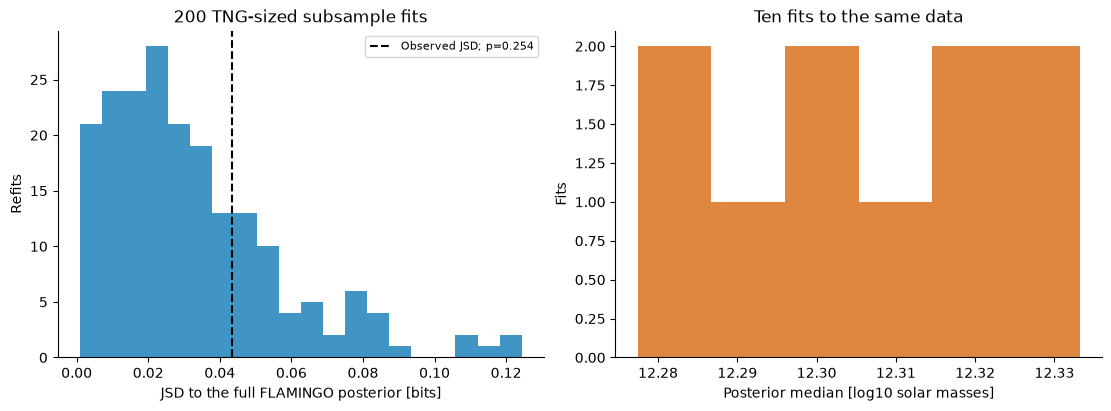

In [3]:
noise = table('bootstrap/noise_comparison.csv')
fixed_fits = table('bootstrap/training_noise_repeats.csv')
ablation_reference = table('ablation/ablation_posterior_discrepancy.csv')
assert len(fixed_fits) == 10
assert np.allclose(ablation_reference.exceedance_fraction, 1/201)
display(noise.round(5))
display(ablation_reference[['variant','mean_w2','reference_median','reference_lower','reference_upper','exceedance_fraction']].round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].hist(refits,bins=20,color='#0072B2',alpha=.75)
axes[0].axvline(observed_jsd,color='black',ls='--',label=f'Observed JSD; p={core_jsd_p:.3f}')
axes[0].set(xlabel='JSD to the full FLAMINGO posterior [bits]',ylabel='Refits',title='200 TNG-sized subsample fits')
axes[0].legend(fontsize=8)
axes[1].hist(fixed_fits.posterior_median,bins=6,color='#D55E00',alpha=.75)
axes[1].set(xlabel='Posterior median [log10 solar masses]',ylabel='Fits',title='Ten fits to the same data')
plt.show()

## Better prediction within one simulation does not guarantee transfer

The feature-block experiment starts with separation, peculiar radial velocity, tangential velocity and the log **bound-subhalo mass ratio**. Morphology adds pair means and differences of stellar velocity dispersion and κcorot. Its FLAMINGO R² rises to 0.922, but falls to 0.612 on the 231 TNG test pairs. The all-features model falls from 0.926 to 0.558.

Removing stellar velocity dispersion reduces the morphology posterior discrepancy from 0.1887 to 0.1162 dex, a 38.4% reduction. Removing κcorot does not have a similar effect. Supporting calibration on all 1530 TNG pairs improves central 68% coverage from 14.8% to 65.8% when dispersion is removed. The ablation identifies an influential input; it does not establish feedback as the cause.

Sources: [block transfer](../results/cross/block_transfer_test.csv), [ablation](../results/ablation/ablation_posterior_discrepancy.csv), [supporting calibration](../results/ablation/supporting_calibration_all1530.csv). Details: [feature diagnostics and ablation](07_feature_diagnostics_and_ablation.ipynb).

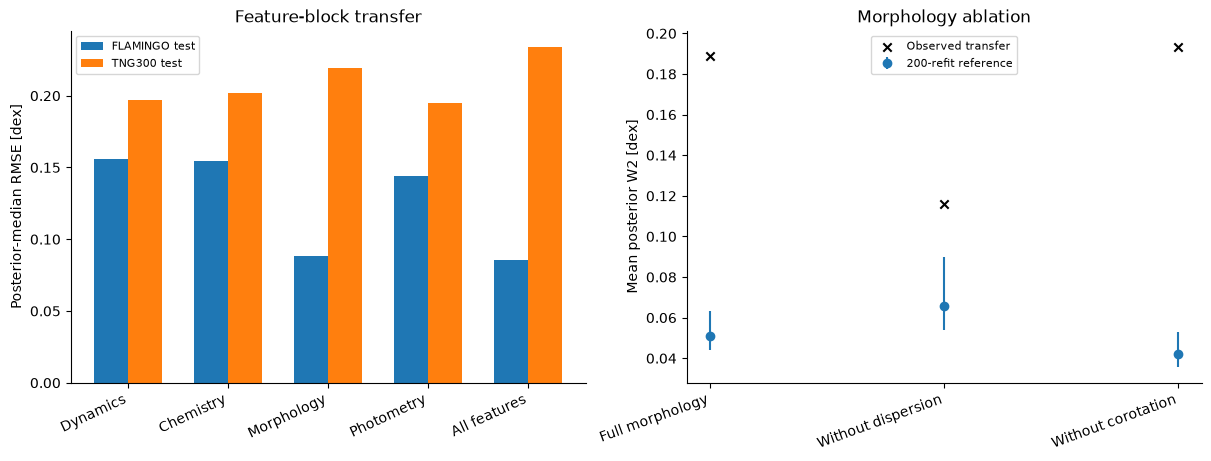

,key,n_test,coverage68,coverage95,bias
0,core_dynamics__full,1530,0.644,0.879,-0.108
1,core_morphology__full,1530,0.148,0.446,-0.194
2,morphology_no_sigma__full,1530,0.658,0.903,-0.092


In [4]:
block = table('cross/block_transfer_test.csv').set_index('block')
ablation = table('ablation/ablation_posterior_discrepancy.csv').set_index('variant')
assert np.isclose(block.loc['core_morphology','within_r2'], .921562, atol=1e-6)
assert np.isclose(block.loc['core_morphology','transfer_r2'], .611857, atol=1e-6)
reduction = 1 - ablation.loc['morphology_no_sigma','mean_w2'] / ablation.loc['core_morphology','mean_w2']
assert np.isclose(reduction, .3844, atol=1e-4)
assert np.allclose(ablation.exceedance_fraction, 1/201)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
labels = ['Dynamics', 'Chemistry', 'Morphology', 'Photometry', 'All features']
x = np.arange(len(block))
axes[0].bar(x-.17, block.within_rmse, width=.34, label='FLAMINGO test')
axes[0].bar(x+.17, block.transfer_rmse, width=.34, label='TNG300 test')
axes[0].set_xticks(x, labels, rotation=25, ha='right')
axes[0].set(ylabel='Posterior-median RMSE [dex]', title='Feature-block transfer')
axes[0].legend(fontsize=8)
variants = ['core_morphology','morphology_no_sigma','morphology_no_kappa']
a = ablation.loc[variants]
x = np.arange(len(a))
axes[1].errorbar(x, a.reference_median,
    yerr=np.vstack([a.reference_median-a.reference_lower, a.reference_upper-a.reference_median]),
    fmt='o', label='200-refit reference')
axes[1].scatter(x, a.mean_w2, marker='x', color='black', label='Observed transfer')
axes[1].set_xticks(x, ['Full morphology','Without dispersion','Without corotation'], rotation=20, ha='right')
axes[1].set(ylabel='Mean posterior W2 [dex]', title='Morphology ablation')
axes[1].legend(fontsize=8, loc='upper center')
plt.show()
display(table('ablation/supporting_calibration_all1530.csv')[['key','n_test','coverage68','coverage95','bias']].round(3))

## Input-distribution differences do not by themselves predict transfer failure

MMD and GMM compare input-feature distributions without using halo-mass targets or posterior predictions. All five block-level MMD tests reach the 1/201 permutation resolution floor, and TNG300 receives a lower mean GMM log-density score in every block. Morphology has the largest per-dimension density deficit, about 0.331, compared with 0.029 for photometry.

The largest individual MMD ratio is for log-metallicity difference, about 65.25 times its reference 95th percentile, yet chemistry transfers more successfully than morphology. Stellar sum also differs, with a ratio of 14.63. Separation is not detected as different by this test (p≈0.100). The dispersion marginals are closer than metallicity or corotation, but their MMD results still detect differences: mean dispersion has p=1/201 and dispersion difference has p=3/201.

Detectable input shifts do not show that a block will fail to transfer successfully. Likewise, similar marginal distributions do not establish a common relationship with halo mass. MMD permutations treat rows independently; they are not a host-component-calibrated significance test.

Sources: thesis §5.5, Tables 5.9–5.10; [individual-feature MMD](../results/feature_space/per_feature_mmd.csv), [block MMD and GMM](../results/feature_space/block_mmd_and_heldout_gmm.csv). Details: [07](07_feature_diagnostics_and_ablation.ipynb).

In [5]:
feature_shift = table('feature_space/per_feature_mmd.csv')
block_shift = table('feature_space/block_mmd_and_heldout_gmm.csv')
assert np.allclose(block_shift.mmd_p,1/201)
assert np.isclose(feature_shift.set_index('feature').loc['separation','p'],20/201)
assert np.isclose(feature_shift.set_index('feature').loc['sigma_diff','p'],3/201)
display(feature_shift[['feature','mmd2','ratio_to_null95','p']].round(4))
display(block_shift[['block','dimensions','mmd2_archived','flamingo_test_mean_loglik_per_dimension',
                     'tng_test_mean_loglik_per_dimension','tng_deficit_per_dimension']].round(4))

,feature,mmd2,ratio_to_null95,p
0,separation,0.0017,0.8472,0.0995
1,vr,0.0439,27.9139,0.0050
2,vt,0.0256,14.3105,0.0050
3,log_mass_ratio,0.0232,13.8742,0.0050
4,sigma_mean,0.0053,2.9636,0.0050
5,sigma_diff,0.0023,1.2878,0.0149
6,kappa_mean,0.0662,38.8955,0.0050
7,kappa_diff,0.0356,16.5230,0.0050
8,met_diff,0.1222,65.2464,0.0050
9,gr_mean,0.0221,12.7797,0.0050


,block,dimensions,mmd2_archived,flamingo_test_mean_loglik_per_dimension,tng_test_mean_loglik_per_dimension,tng_deficit_per_dimension
0,core_dynamics,4,0.0373,-1.3297,-1.4856,0.1558
1,core_chemistry,5,0.0539,-1.3465,-1.4520,0.1055
2,core_morphology,8,0.0612,-1.2248,-1.5562,0.3314
3,core_photometry,6,0.0254,-1.2373,-1.2663,0.0290
4,all_features,11,0.0572,-1.1804,-1.4860,0.3056


## Absolute stellar mass makes transfer bias much worse

The six final models use **dynamics = [r, vr, vt]**, with or without `log10(Mstar,a + Mstar,b)`. This dynamics definition omits the bound-mass ratio used in the feature-block experiment. The three training populations are FLAMINGO, TNG300 and an equal-domain combined sample.

Adding stellar sum reduces in-domain RMSE from 0.2343 to 0.1316 dex in FLAMINGO and from 0.3038 to 0.1487 dex in TNG300. Across simulations, however, the stellar-sum bias is −0.3164 dex for FLAMINGO→TNG300 and +0.3214 dex for TNG300→FLAMINGO. Central 68% intervals cover only 19.9% and 10.1% of the true masses, respectively. RMSE alone therefore does not tell the complete story.

The combined model reduces some transfer errors, but residual biases remain. On the 48 different-host TNG test pairs, the FLAMINGO stellar-sum model has zero 68% coverage. Pooled performance should not be assumed to represent this small Local Group-like stratum.

Sources: [six-model metrics](../results/final_six/six_model_metrics.csv). Details: [transfer](04_within_and_cross_simulation.ipynb) and [calibration](05_calibration.ipynb).

In [6]:
metrics = table('final_six/six_model_metrics.csv')
pooled = metrics.query("subset == 'pooled'").copy()
def metric(model, domain):
    return pooled.loc[(pooled.model == model) & (pooled.domain == domain)].iloc[0]
assert np.isclose(metric('flamingo_dynamics','flamingo').rmse, .234264, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','flamingo').rmse, .131649, atol=1e-6)
assert np.isclose(metric('tng_dynamics','tng').rmse, .303766, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','tng').rmse, .148660, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','tng').bias, -.316399, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','flamingo').bias, .321360, atol=1e-6)
assert np.isclose(metric('flamingo_stellar_sum','tng').coverage68, .199134, atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','flamingo').coverage68, .100892, atol=1e-6)
diff = metrics.query("model == 'flamingo_stellar_sum' and domain == 'tng' and subset == 'different_host'").iloc[0]
assert diff.n == 48 and diff.coverage68 == 0
show = pooled[['model','domain','n','rmse','bias','r2','coverage68','coverage95']].copy()
show[['coverage68','coverage95']] *= 100
show = show.rename(columns={'coverage68':'68% coverage [%]','coverage95':'95% coverage [%]'})
display(show.round(3).reset_index(drop=True))

,model,domain,n,rmse,bias,r2,68% coverage [%],95% coverage [%]
0,combined_dynamics,flamingo,21409,0.263,0.087,0.308,74.726,95.759
1,combined_dynamics,tng,231,0.319,-0.072,0.178,73.160,91.775
2,combined_stellar_sum,flamingo,21409,0.189,0.095,0.643,71.283,94.979
3,combined_stellar_sum,tng,231,0.208,-0.122,0.649,64.069,90.043
4,flamingo_dynamics,flamingo,21409,0.234,-0.003,0.450,72.839,94.054
5,flamingo_dynamics,tng,231,0.365,-0.155,-0.081,64.935,85.281
6,flamingo_stellar_sum,flamingo,21409,0.132,-0.002,0.826,69.634,94.713
7,flamingo_stellar_sum,tng,231,0.360,-0.316,-0.050,19.913,49.784
8,tng_dynamics,flamingo,21409,0.334,0.195,-0.119,60.456,94.021
9,tng_dynamics,tng,231,0.304,-0.006,0.253,71.861,93.939


## Coverage exposes a transfer failure that RMSE can hide

For the stellar-sum models, central 95% intervals cover only 49.8% of TNG truths under the FLAMINGO model and 33.4% of FLAMINGO truths under the TNG model. The mean 68% interval widths remain about 0.306 and 0.269 dex while the absolute biases are about 0.316 and 0.321 dex. The intervals are too narrow relative to the directional errors.

Within-simulation coverage is substantially better, but it is not a guarantee of calibration for every individual posterior. The combined models also retain opposite domain biases; pooled or equal-domain coverage can hide their cancellation. These are held-out coverage and rank diagnostics inspired by SBC, not a formal prior-predictive SBC experiment.

Source: thesis §5.4; [coverage, ranks and widths](../results/calibration/final_calibration_with_binomial_intervals.csv). Details: [05](05_calibration.ipynb).

In [7]:
calibration_table = table('calibration/final_calibration_with_binomial_intervals.csv').query("subset == 'pooled'")
assert np.isclose(metric('flamingo_stellar_sum','tng').coverage95,.497835,atol=1e-6)
assert np.isclose(metric('tng_stellar_sum','flamingo').coverage95,.333785,atol=1e-6)
display(calibration_table[['model','domain','coverage68','coverage95','mean_width68','rank_cdf_distance']].round(3))

,model,domain,coverage68,coverage95,mean_width68,rank_cdf_distance
0,combined_dynamics,flamingo,0.747,0.958,0.553,0.158
1,combined_dynamics,tng,0.732,0.918,0.545,0.115
4,combined_stellar_sum,flamingo,0.713,0.950,0.358,0.217
5,combined_stellar_sum,tng,0.641,0.900,0.369,0.267
8,flamingo_dynamics,flamingo,0.728,0.941,0.440,0.035
9,flamingo_dynamics,tng,0.649,0.853,0.470,0.203
12,flamingo_stellar_sum,flamingo,0.696,0.947,0.254,0.015
13,flamingo_stellar_sum,tng,0.199,0.498,0.306,0.654
16,tng_dynamics,flamingo,0.605,0.940,0.592,0.279
17,tng_dynamics,tng,0.719,0.939,0.559,0.086


## Stellar normalization removes much of the measured bias

A training-only regression of summed bound mass gives a calibrated stellar-input shift of **+0.3617 dex**, with component-bootstrap 95% interval **[0.3527, 0.3693]**. On the same 231 TNG test pairs, the separate stellar-sum checkpoint improves from RMSE 0.3595 to 0.1599 dex, while the individual-stellar checkpoint improves from 0.3422 to 0.1368 dex.

The shift is applied before feature scaling. It was calibrated without selecting the value that minimizes held-out M200c error. The evaluation includes paired component-bootstrap intervals. This is a sensitivity test, not a correction to measured Local Group stellar masses or proof of a unique physical cause. These checkpoints are separate from the six-model comparison above.

Source: thesis §5.7 and Table 5.13; [stellar-shift results](../results/competing/delta_zero_and_calibrated.csv), [paired differences](../results/competing/delta_point_changes_with_intervals.csv). Details: [09](09_stellar_normalization.ipynb).

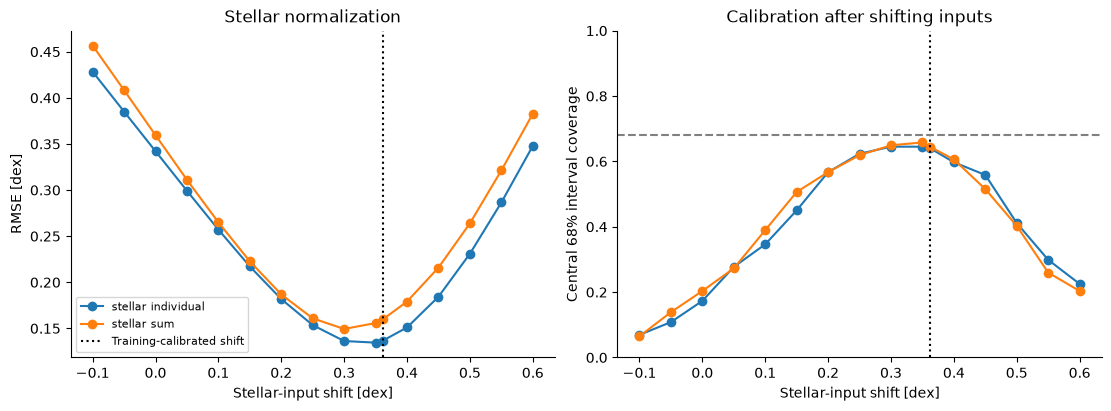

,model,delta,n,rmse,bias,coverage68,coverage95
0,stellar_sum,0.000,231,0.360,-0.316,0.203,0.541
1,stellar_sum,0.362,231,0.160,0.043,0.645,0.922
2,stellar_individual,0.000,231,0.342,-0.301,0.173,0.537
3,stellar_individual,0.362,231,0.137,0.025,0.641,0.935


,model,metric,estimate,lower95,upper95
0,stellar_sum,rmse,-0.1997,-0.2270,-0.1709
1,stellar_sum,bias,0.3593,0.3447,0.3746
2,stellar_sum,coverage68,0.4416,0.3435,0.5322
3,stellar_individual,rmse,-0.2054,-0.2292,-0.1793
4,stellar_individual,bias,0.3252,0.3108,0.3399
5,stellar_individual,coverage68,0.4675,0.3668,0.5622


In [8]:
# These are the separate stellar-sum and individual-stellar checkpoints.

cal = record('competing/delta_calibration.json')
assert np.isclose(cal['delta'], .36168937856918487)
shift = table('competing/delta_full_sensitivity.csv').query("subset == 'pooled'")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for model, part in shift.groupby('model'):
    part = part.sort_values('delta')
    axes[0].plot(part.delta, part.rmse, 'o-', label=model.replace('_',' '))
    axes[1].plot(part.delta, part.coverage68, 'o-', label=model.replace('_',' '))
for ax in axes:
    ax.axvline(cal['delta'], color='black', ls=':', label='Training-calibrated shift')
    ax.set_xlabel('Stellar-input shift [dex]')
axes[0].set(ylabel='RMSE [dex]', title='Stellar normalization')
axes[1].set(ylabel='Central 68% interval coverage', ylim=(0, 1), title='Calibration after shifting inputs')
axes[1].axhline(.68, color='gray', ls='--')
axes[0].legend(fontsize=8)
plt.show()
shift_summary = table('competing/delta_zero_and_calibrated.csv').query("subset == 'pooled'")
assert np.isclose(shift_summary.query("model == 'stellar_sum' and calibrated").iloc[0].rmse,.159866,atol=1e-6)
assert np.isclose(shift_summary.query("model == 'stellar_individual' and calibrated").iloc[0].rmse,.136754,atol=1e-6)
display(shift_summary[['model','delta','n','rmse','bias','coverage68','coverage95']].round(3).reset_index(drop=True))
display(table('competing/delta_point_changes_with_intervals.csv').round(4))

## Common support does not remove the absolute-stellar transfer bias

If transfer failure came only from comparing different input populations, performance should improve for systems that are difficult to distinguish by their inputs. The common-support experiment tests this with feature-only domain scores: FLAMINGO=0 and TNG300=1, with inverse-frequency weights giving the two simulations equal total weight. Five-fold cross-validation grouped by connected host component produces out-of-fold scores. The main overlap band is **0.4≤s(x)≤0.6**.

Five input configurations were tested: dynamics only, dynamics plus bound-mass ratio, individual stellar masses, stellar ratio and stellar sum. The posterior evaluation starts with 21409 held-out FLAMINGO pairs and **all 1530 TNG pairs**. It is a separate follow-up from the final-six 231-row TNG comparison. Morphology was not tested under this common-support procedure.

The classifier distinguishes absolute-stellar inputs more strongly (AUC≈0.81) than dynamics (AUC≈0.63). In the main band, the TNG retained counts are 957, 629, 298, 849 and 311 for the five configurations. For stellar sum, restriction changes RMSE from **0.3485 to 0.3708 dex**, bias from **−0.3036 to −0.3214 dex**, and 68% coverage from **21.0% to 18.6%**. Individual stellar masses retain a bias of −0.2956 dex and coverage of 19.1%. Within the stellar-sum band, the FLAMINGO held-out sample still has RMSE 0.1452 dex, bias +0.0019 dex and C68 of 70.2%, while the TNG sample remains strongly biased. The disagreement persists in the classifier overlap region.

Sources: thesis §§4.10 and 5.7, Tables 4.3 and 5.14; [domain discrimination](../results/competing/classifier_discrimination.csv), [common-support results](../results/competing/common_support_main.csv). Details: [10](10_common_support.ipynb).

In [9]:
common = table('competing/common_support_main.csv')
order = ['dynamics','bound_subhalo_ratio','stellar_individual','stellar_ratio','stellar_sum']
labels = ['Dynamics','Dynamics + bound ratio','Dynamics + individual stars','Dynamics + stellar ratio','Dynamics + stellar sum']
inside = common.query("population == 'transfer_tng' and half_width == .1").set_index('feature_space').loc[order]
outside = common.query("population == 'transfer_tng' and half_width == .5").set_index('feature_space').loc[order]
source_overlap = common.query("population == 'source_heldout' and half_width == .1").set_index('feature_space').loc[order]
auc = table('competing/classifier_discrimination.csv').set_index('feature_space').loc[order]
assert inside.n.tolist() == [957,629,298,849,311]
assert source_overlap.n.tolist() == [12055,8209,4215,10594,4253]
assert set(inside.n_total) == {1530}
assert np.isclose(inside.loc['stellar_sum','bias'],-.321432,atol=1e-6)
retention = pd.DataFrame({'Input configuration':labels,'FLAMINGO retained':source_overlap.n.to_numpy(),
    'TNG retained':inside.n.to_numpy(),'TNG retained [%]':100*inside.retained_fraction.to_numpy(),
    'OOF ROC AUC':auc.roc_auc.to_numpy()})
display(retention.round(3))
comparison = pd.DataFrame({'Input configuration':labels,'RMSE all':outside.rmse.to_numpy(),
    'RMSE overlap':inside.rmse.to_numpy(),'Bias all':outside.bias.to_numpy(),'Bias overlap':inside.bias.to_numpy(),
    'C68 all [%]':100*outside.coverage68.to_numpy(),'C68 overlap [%]':100*inside.coverage68.to_numpy()})
display(comparison.round(3))
source_check = source_overlap[['n','rmse','bias','coverage68']].copy()
assert np.isclose(source_check.loc['stellar_sum','bias'],.001911,atol=1e-6)
source_check['coverage68'] *= 100
source_check.index = labels
display(source_check.rename(columns={'n':'FLAMINGO overlap pairs','coverage68':'C68 [%]'}).round(3))


,Input configuration,FLAMINGO retained,TNG retained,TNG retained [%],OOF ROC AUC
0,Dynamics,12055,957,62.549,0.632
1,Dynamics + bound ratio,8209,629,41.111,0.688
2,Dynamics + individual stars,4215,298,19.477,0.812
3,Dynamics + stellar ratio,10594,849,55.490,0.648
4,Dynamics + stellar sum,4253,311,20.327,0.809


,Input configuration,RMSE all,RMSE overlap,Bias all,Bias overlap,C68 all [%],C68 overlap [%]
0,Dynamics,0.368,0.377,-0.153,-0.157,66.667,66.980
1,Dynamics + bound ratio,0.201,0.206,-0.108,-0.110,64.379,62.639
2,Dynamics + individual stars,0.331,0.342,-0.289,-0.296,19.804,19.128
3,Dynamics + stellar ratio,0.321,0.325,-0.170,-0.179,62.092,60.542
4,Dynamics + stellar sum,0.348,0.371,-0.304,-0.321,21.046,18.650


,FLAMINGO overlap pairs,rmse,bias,C68 [%]
Dynamics,12055,0.244,-0.000,71.273
Dynamics + bound ratio,8209,0.162,-0.000,67.682
Dynamics + individual stars,4215,0.132,0.005,69.158
Dynamics + stellar ratio,10594,0.209,-0.010,70.191
Dynamics + stellar sum,4253,0.145,0.002,70.162


### The conclusion is not tied to one score-band choice

Narrowing or widening the classifier band changes the number and target distribution of the retained pairs. The saved sensitivity test reports bands from 0.45–0.55 through the unrestricted sample. The absolute-stellar bias and low coverage persist across those choices.

A score near 0.5 does not exactly match every covariate, and the classifier has finite accuracy. The common-support result weakens an explanation based only on the feature-support differences detected by this classifier. It does not prove identical input distributions or identify a physical source of conditional shift. Retained counts, bias, coverage and interval widths need to be read together.

Source: thesis Figure 5.5; [score-band sensitivity](../results/competing/common_support_band_sensitivity.csv).

,min_pairs,max_pairs,minimum_bias,maximum_bias,minimum_C68,maximum_C68
feature_space,,,,,,
stellar_individual,151,1530,-0.299,-0.288,0.172,0.199
stellar_sum,174,1530,-0.321,-0.302,0.186,0.211


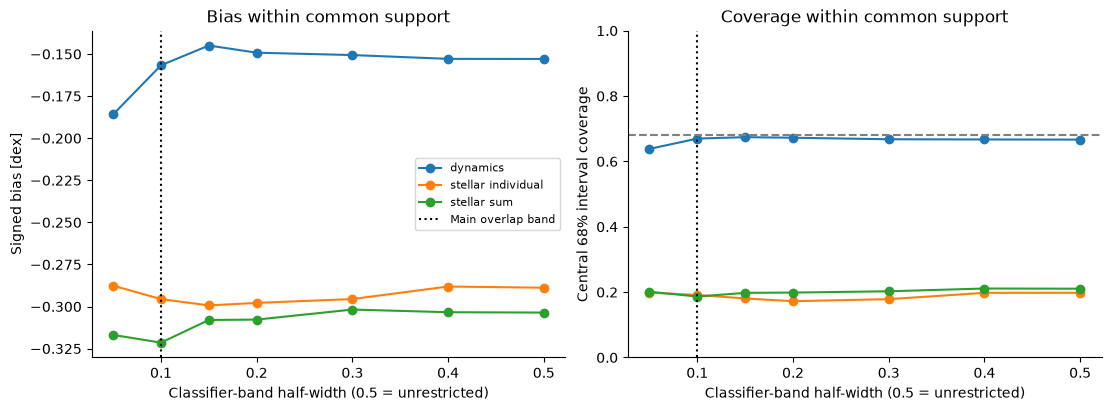

In [10]:
bands = table('competing/common_support_band_sensitivity.csv')
stars = bands.loc[bands.feature_space.isin(['stellar_individual','stellar_sum'])]
assert (stars.bias < 0).all() and (stars.coverage68 < .25).all()
display(stars.groupby('feature_space').agg(min_pairs=('n','min'),max_pairs=('n','max'),
    minimum_bias=('bias','min'),maximum_bias=('bias','max'),
    minimum_C68=('coverage68','min'),maximum_C68=('coverage68','max')).round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for feature in ['dynamics','stellar_individual','stellar_sum']:
    part=bands.loc[bands.feature_space == feature].sort_values('half_width')
    label=feature.replace('_',' ')
    axes[0].plot(part.half_width,part.bias,'o-',label=label)
    axes[1].plot(part.half_width,part.coverage68,'o-',label=label)
for ax in axes:
    ax.axvline(.1,color='black',ls=':',label='Main overlap band')
    ax.set_xlabel('Classifier-band half-width (0.5 = unrestricted)')
axes[0].set(ylabel='Signed bias [dex]',title='Bias within common support')
axes[1].axhline(.68,color='gray',ls='--')
axes[1].set(ylabel='Central 68% interval coverage',ylim=(0,1),title='Coverage within common support')
axes[0].legend(fontsize=8);plt.show()

## Alternative targets and training priors do not provide a complete explanation

Replacing M200c with the sum of the two bound-subhalo masses makes the target definition consistent across host classes. On all 1530 TNG pairs, the absolute-stellar configurations still have biases near −0.36 dex and only 1.6% coverage for nominal 68% intervals. The stellar-ratio configuration transfers more successfully. Changing the mass target alone therefore does not restore transfer or harmonize the input definitions and halo finders.

The training-prior diagnostic discussed in the thesis also matters. Reweighting saved draws to the other simulation's training-only empirical mass prior changes forward dynamics bias from −0.1554 to +0.0076 dex, but the stellar-sum bias remains −0.2490 dex and C68 is only 31.6%. Reverse-direction reweighting can have very low effective sample size, and results depend on the KDE bandwidth. This is an assumption-dependent sensitivity test, not proof that the simulations share the same likelihood mapping.

The declared [11.5,14.5] box restricts posterior sampling; it does not make the catalogue training masses uniform. Prior, covariate and conditional differences should not be treated as interchangeable explanations.

Sources: thesis §5.7, Table 5.13 and discussion §6.2; [alternative target](../results/competing/alternative_target.csv), [prior swaps](../results/prior/prior_swap_main_table.csv). Details: notebooks [08](08_alternative_mass_targets.ipynb) and [11](11_prior_and_support_sensitivity.ipynb).

In [11]:
alt = table('competing/alternative_target.csv')
assert set(alt.n) == {1530}
assert np.isclose(alt.loc[alt.mass_feature == 'stellar_sum','bias'].iloc[0],-.362768,atol=1e-6)
display(alt[['mass_feature','n','rmse','bias','coverage68','coverage95']].round(3))
prior = table('prior/prior_swap_main_table.csv')
forward = prior.loc[prior.model.isin(['flamingo_dynamics','flamingo_stellar_sum'])]
assert np.isclose(forward.query("model == 'flamingo_dynamics' and treatment == 'prior_swap'").iloc[0].bias,.007598,atol=1e-6)
assert np.isclose(forward.query("model == 'flamingo_stellar_sum' and treatment == 'prior_swap'").iloc[0].bias,-.248986,atol=1e-6)
display(forward[['model','treatment','n','rmse','bias','coverage68','ess_median','ess_min']].round(3).reset_index(drop=True))

,mass_feature,n,rmse,bias,coverage68,coverage95
0,none,1530,0.355,-0.186,0.690,0.863
1,stellar_individual,1530,0.379,-0.357,0.016,0.253
2,stellar_ratio,1530,0.320,-0.192,0.654,0.875
3,stellar_sum,1530,0.384,-0.363,0.016,0.250


,model,treatment,n,rmse,bias,coverage68,ess_median,ess_min
0,flamingo_dynamics,original,231,0.365,-0.155,0.649,500.000,500.000
1,flamingo_dynamics,prior_swap,231,0.356,0.008,0.662,365.029,1.000
2,flamingo_stellar_sum,original,231,0.360,-0.316,0.199,500.000,500.000
3,flamingo_stellar_sum,prior_swap,231,0.307,-0.249,0.316,396.042,189.241


## The Local Group estimates remain simulation-dependent

Dynamics-only estimates agree closely, with nominal medians of approximately **3.0–3.2×10¹² solar masses**, but their posteriors are broad. Adding stellar mass leaves FLAMINGO near **3.0×10¹²**, moves TNG300 to **5.6×10¹²**, and gives a combined median near **3.2×10¹²**. The specialist median gap grows from 0.037 dex to 0.274 dex. Approximate propagation of input uncertainty changes the medians by less than 0.009 dex, much less than the stellar-conditioned disagreement.

The nominal estimates contain 100000 posterior draws. Input mixtures average 20 conditional draws for each of 5000 independently sampled observational realizations. They approximate uncertainty propagation rather than exact observational marginalization. Observed stellar proxies and all-bound catalogue stellar masses also have different definitions.

The networks do not condition on host membership: same-host pairs use a common host M200c and different-host pairs use the sum of two host masses. The real MW–M31 system is different-host. Pooled feature support does not establish support for that intended two-host inference.

Source: [Local Group posterior summary](../results/local_group/local_group_posterior_summary.csv). Details: [Local Group and interpretation](12_local_group_and_interpretation.ipynb).

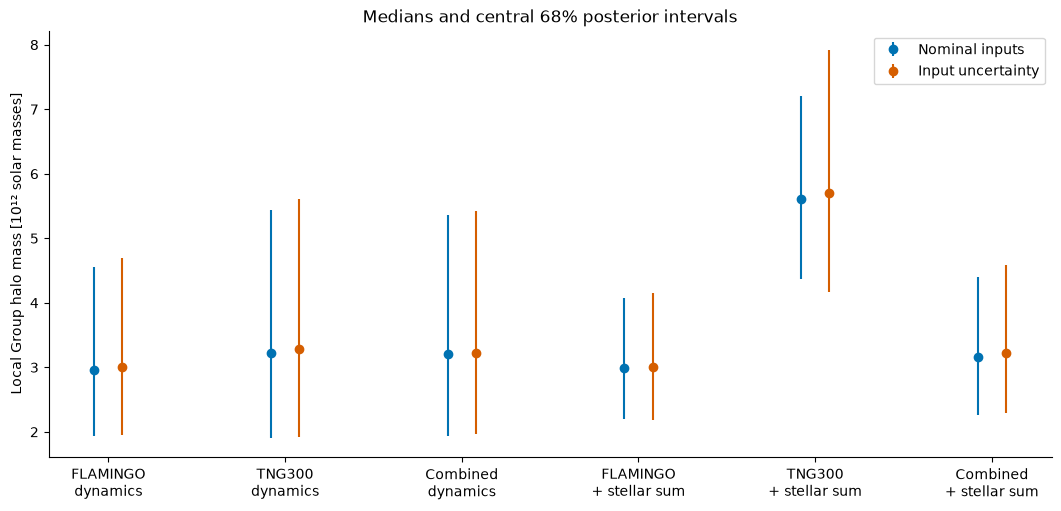

,model,inference_type,16th percentile,Median,84th percentile
0,flamingo_dynamics,nominal,1.94,2.96,4.55
1,flamingo_dynamics,observational_uncertainty,1.95,3.01,4.69
2,flamingo_stellar_sum,nominal,2.19,2.99,4.07
3,flamingo_stellar_sum,observational_uncertainty,2.18,3.01,4.15
4,tng_dynamics,nominal,1.91,3.23,5.43
5,tng_dynamics,observational_uncertainty,1.93,3.28,5.61
6,tng_stellar_sum,nominal,4.36,5.61,7.20
7,tng_stellar_sum,observational_uncertainty,4.17,5.70,7.92
8,combined_dynamics,nominal,1.93,3.21,5.36
9,combined_dynamics,observational_uncertainty,1.97,3.23,5.42


In [12]:
lg = table('local_group/local_group_posterior_summary.csv')
keys = ['flamingo_dynamics','tng_dynamics','combined_dynamics',
        'flamingo_stellar_sum','tng_stellar_sum','combined_stellar_sum']
nominal = lg.query("inference_type == 'nominal'").set_index('model')
mixture = lg.query("inference_type == 'observational_uncertainty'").set_index('model')
assert np.isclose(nominal.loc['tng_stellar_sum','mass_median_msun']/1e12, 5.611565, atol=1e-6)
assert np.max(np.abs(mixture.loc[keys,'log_median']-nominal.loc[keys,'log_median'])) < .009
assert np.isclose(nominal.loc['tng_stellar_sum','log_median']-nominal.loc['flamingo_stellar_sum','log_median'], .27399, atol=1e-5)
fig, ax = plt.subplots(figsize=(10.5, 5), layout='constrained')
for offset, data, label, colour in [(-.08,nominal,'Nominal inputs','#0072B2'),
                                    (.08,mixture,'Input uncertainty','#D55E00')]:
    d = data.loc[keys]
    median = d.mass_median_msun.to_numpy()/1e12
    low = d.mass_q16_msun.to_numpy()/1e12
    high = d.mass_q84_msun.to_numpy()/1e12
    ax.errorbar(np.arange(len(keys))+offset, median,
                yerr=np.vstack([median-low,high-median]), fmt='o', color=colour, label=label)
ax.set_xticks(np.arange(len(keys)), ['FLAMINGO\ndynamics','TNG300\ndynamics','Combined\ndynamics',
                                    'FLAMINGO\n+ stellar sum','TNG300\n+ stellar sum','Combined\n+ stellar sum'])
ax.set(ylabel='Local Group halo mass [10¹² solar masses]', title='Medians and central 68% posterior intervals')
ax.legend();plt.show()
summary = lg[['model','inference_type','mass_q16_msun','mass_median_msun','mass_q84_msun']].copy()
summary[['mass_q16_msun','mass_median_msun','mass_q84_msun']] /= 1e12
summary = summary.rename(columns={'mass_q16_msun':'16th percentile','mass_median_msun':'Median','mass_q84_msun':'84th percentile'})
display(summary.round(2).reset_index(drop=True))

## What the results establish

In the tested morphology and absolute-stellar experiments, inputs that improve within-simulation prediction also reduce cross-simulation robustness. The morphology ablation identifies sensitivity to stellar velocity dispersion, while the stellar-input experiments identify sensitivity to absolute normalization. These findings do not establish that every informative feature transfers poorly or identify a unique physical mechanism. Similar marginal input distributions do not establish that the joint relationship with mass transfers.

The results do not establish which simulation gives the correct Local Group mass. Feedback, resolution, halo finding, cosmology and selection vary together; neither agreement within one simulation nor balanced combined training proves physical accuracy. No consensus Local Group mass is given because of the simulation dependence of the posteriors.

## Completed in the thesis, and what remains future work

The thesis covered population and sample-size comparisons; within-simulation prediction; both directions of transfer in the six-model comparison; calibration; input-distribution diagnostics; feature ablation; alternative mass targets; stellar normalization; common support; training-prior sensitivity; and the observed Local Group with approximate input-uncertainty propagation. These experiments identify transfer-sensitive inputs and test several competing explanations. They do not isolate one physical cause or establish which simulation is correct.

| Completed comparison | What it established or limited |
|---|---|
| Population KS, posterior subsampling and training-noise references | The population and ablation differences exceed their tested sample-size references; core-dynamics JSD is consistent with its refit reference. |
| Feature-block and six-model experiments | Strong within-simulation performance can coexist with biased, overconfident transfer. |
| Morphology ablations | Removing dispersion improves posterior agreement and calibration; adding a same-host indicator to that block did not repair it. |
| Alternative targets, stellar shifts and common support | Target convention and coarse classifier support alone do not explain the absolute-stellar failure; normalization sensitivity is substantial. |
| Empirical-prior diagnostics and Local Group application | The empirical training population matters, but neither reweighting nor pooled agreement selects a correct physical Local Group mass. |
| Earlier dynamics density-family and host-specific fits | These limited comparisons were performed; they do not settle flexible-density or host-conditioned inference for the final stellar/combined Local Group models. |

The following remain future work. They were not completed as controlled tests in this thesis:

| Follow-up experiment | Question that remains open | Main requirement or caveat |
|---|---|---|
| Controlled FLAMINGO feedback, resolution and cosmology variants | Which simulation choices move stellar normalization and transfer calibration? | m8/m9 resolution changes also involve recalibration; morphology may be poorly resolved at m9. Feedback and calibration parameters can vary together. |
| A common finder and common stellar apertures | How much of the difference comes from membership, centring or measurement definitions? | Requires suitable snapshots/particles and recomputation; changing M200c alone does not harmonize input features. |
| Halo-mass-based selection from parent catalogues | Does the stellar-mass window alter the selected populations at fixed halo mass? | Selected caches omit excluded objects, so a new parent-catalogue selection is needed. |
| A third simulation | Does the transfer pattern generalize beyond FLAMINGO and TNG300? | Requires another feature/selection pipeline and independent evaluation. |
| Different-host or host-conditioned final Local Group models | Does matching the intended two-host target improve inference? | Earlier host-specific block fits and the host-indicator ablation do not answer this for the final Local Group models; TNG has only 48 different-host test pairs. |
| Flexible final stellar/combined densities and repeated seeds | Does the conditional-Gaussian restriction or fitting variability affect calibration and mixture shape? | Earlier dynamics-only MAF/NSF/MDN comparisons are insufficient; new fits are needed. |
| Catalogue-level domain adaptation or robust SBI | Can sensitivity to dispersion and absolute stellar mass be reduced without discarding useful information? | Requires separate tuning and validation across simulations, rather than assuming a correction succeeds. |

All of these experiments remain future work and were not included either due to limited availability of compute, time, or data. The separate [classifier-mixture notebook](13_classifier_mixture_posteriors.ipynb) is an extension, rather than an additional thesis result.

Source: thesis §§6.3, 6.6 and 6.7, Tables 6.3 and 6.5.

[Full notebook sequence](00_start_here.ipynb) · [Thesis table and figure map](../docs/thesis_map.ipynb) · [Repository overview](../README.md)